[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JMasr/ai-tutorials/blob/main/es/whisper-rlora.ipynb)

Autor: José Manuel Ramírez Sánchez · https://jmramirez.engineer

# Radial LoRA (R-LoRA) sobre Whisper, implementado desde cero

Este notebook implementa **R-LoRA (Radial Low-Rank Adaptation)** en PyTorch puro y lo
aplica a un modelo **Whisper**, siguiendo los mismos pasos que el tutorial
[PEFT + LoRA sobre Whisper](https://github.com/JMasr/ai-tutorials/blob/main/es/whisper-peft-lora.ipynb):
un clasificador vía *downstream task* (Parte A) y un extractor de embeddings
(Parte B), con los mismos datos sintéticos, para poder leer los dos notebooks en paralelo.

R-LoRA es un cambio de un parámetro sobre LoRA: antes de la proyección de bajo
rango, la entrada del adaptador se divide por su norma elevada a un exponente
aprendible λ ∈ [0, 1]. Se presentó para voz clínica con pocos datos
(IberSPEECH 2026), donde supera a LoRA en 12,4 puntos de Macro-F1 en cuatro
corpus, y se usó para adaptar Whisper-large-v3 en el reto de reconocimiento de
voz de ALBAYZIN 2026. La librería `peft` no lo incluye, así que aquí se escribe
como un pequeño `nn.Module` que envuelve cualquier `nn.Linear`; eso también
significa que funciona en cualquier Transformer, no solo en Whisper.

**Qué vas a hacer:**
1. Escribir `RLoRALinear` y comprobar numéricamente sus tres propiedades.
2. Inyectarlo en el encoder de Whisper y entrenar un clasificador, junto a un
   LoRA de referencia con el mismo rango.
3. Leer los exponentes λ que aprende el modelo, guardar y recargar el adaptador,
   y ver por qué no se puede fusionar con los pesos.
4. Repetir la receta del extractor de embeddings del tutorial de LoRA con R-LoRA.

**Diseño del notebook:** solo CPU, tonos sintéticos, `openai/whisper-tiny`.

> Tiempo total estimado: **~4 minutos** en una CPU de 8 núcleos sin GPU (incluida la descarga del modelo).

**Requisitos:** instala las dependencias antes de empezar (en Colab, ejecútalo en una celda como `%pip install ...`):

```bash
pip install torch transformers==4.57.6 peft==0.20.0 scikit-learn matplotlib
```

## 0. R-LoRA en una página

LoRA congela un peso preentrenado $W_0 \in \mathbb{R}^{d\times k}$ y añade una actualización de bajo rango:

$$ h = W_0 x + \tfrac{\alpha}{r}\, B A x, \qquad B \in \mathbb{R}^{d\times r},\ A \in \mathbb{R}^{r\times k},\ r \ll \min(d,k) $$

Esa actualización es **lineal en $x$**: responde tanto al tamaño de una activación como a
la dirección en la que apunta. Dentro de un Transformer, la normalización de capa mantiene
los estados ocultos sobre una esfera y, en muchas dimensiones, los ángulos informan más que
las distancias. R-LoRA condiciona la actualización a la dirección atemperando la norma de la entrada:

$$ T_\lambda(x) = \frac{x}{(\lVert x\rVert_2 + \varepsilon)^{\lambda}}, \qquad \lambda = \sigma(\lambda_{\text{raw}}) \in [0, 1], \qquad h = W_0 x + \tfrac{\alpha}{r}\, B A\, T_\lambda(x) $$

| λ | Qué ve la rama |
|---|---|
| 0 | la entrada tal cual: LoRA normal |
| 1 | la entrada proyectada sobre la esfera unidad: solo la dirección |
| intermedio | la dirección y parte de la magnitud |

- **Un escalar aprendible por capa adaptada** ($\lambda_{\text{raw}}$), además de los $r(d+k)$ de LoRA.
- **La misma inicialización que LoRA**: $A$ Kaiming-uniforme, $B = 0$, así que el entrenamiento
  parte exactamente del modelo preentrenado. $\lambda_{\text{raw}} = 0.5$, es decir, $\lambda_0 \approx 0.62$.
- **El precio**: $T_\lambda$ no es lineal, así que la actualización no se puede plegar en $W_0$ tras
  entrenar; la rama se ejecuta en cada pasada (menos de un 1 % de tiempo extra en el paper).

In [1]:
import os

# Fuerza CPU de forma explícita, como en el tutorial de LoRA.
os.environ["CUDA_VISIBLE_DEVICES"] = ""

import math
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)
DEVICE = torch.device("cpu")

import peft
import transformers

transformers.logging.set_verbosity_error()
print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)
print("peft        :", peft.__version__, "(solo para el LoRA de referencia)")

torch       : 2.14.0+cpu
transformers: 4.57.6
peft        : 0.20.0 (solo para el LoRA de referencia)


## 1. Datos sintéticos y features

Los mismos datos que el tutorial de LoRA: tonos senoidales de 1 segundo a 16 kHz, dos clases
definidas por su frecuencia base, más ruido gaussiano. Se convierten en la entrada log-mel de
Whisper, siempre rellenada a 30 segundos (3000 frames).

In [2]:
from transformers import WhisperFeatureExtractor

SAMPLE_RATE = 16_000
DURATION_S = 1.0
CLASS_FREQS = (220.0, 660.0)
NOISE_STD = 0.05
CHECKPOINT = "openai/whisper-tiny"


def make_example(label: int, rng: np.random.Generator) -> np.ndarray:
    t = np.linspace(0, DURATION_S, int(SAMPLE_RATE * DURATION_S), endpoint=False)
    freq = CLASS_FREQS[label] * (1 + 0.05 * rng.standard_normal())
    wave = 0.3 * np.sin(2 * np.pi * freq * t) + NOISE_STD * rng.standard_normal(t.shape)
    return wave.astype(np.float32)


def make_dataset(n_per_class: int, seed: int) -> tuple[list[np.ndarray], list[int]]:
    rng = np.random.default_rng(seed)
    waves, labels = [], []
    for label in (0, 1):
        for _ in range(n_per_class):
            waves.append(make_example(label, rng))
            labels.append(label)
    return waves, labels


feature_extractor = WhisperFeatureExtractor.from_pretrained(CHECKPOINT)


def to_batch(waves, labels):
    feats = feature_extractor(waves, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    return feats["input_features"], torch.tensor(labels)


X_train, y_train = to_batch(*make_dataset(n_per_class=10, seed=2))
X_val, y_val = to_batch(*make_dataset(n_per_class=4, seed=3))
print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape))

train: (20, 80, 3000) | val: (8, 80, 3000)


## 2. Implementar R-LoRA

`RLoRALinear` envuelve una `nn.Linear` existente. La capa envuelta queda congelada; el módulo
añade `lora_A`, `lora_B` y un escalar `lambda_raw`. La pasada hacia delante es la ecuación de
arriba, línea a línea.

In [3]:
class RLoRALinear(nn.Module):
    """Una nn.Linear congelada más una rama radial de bajo rango: h = W0 x + (alpha/r) B A T_lambda(x)."""

    def __init__(self, base: nn.Linear, r: int = 8, alpha: float = 16.0,
                 dropout: float = 0.0, lambda_raw_init: float = 0.5, eps: float = 1e-6):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        self.lora_A = nn.Linear(base.in_features, r, bias=False)
        self.lora_B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.lora_A.weight, a=math.sqrt(5))  # como en LoRA
        nn.init.zeros_(self.lora_B.weight)                              # la rama empieza en cero
        self.lambda_raw = nn.Parameter(torch.tensor(float(lambda_raw_init)))
        self.scaling = alpha / r
        self.dropout = nn.Dropout(dropout)
        self.eps = eps

    @property
    def lam(self) -> torch.Tensor:
        return torch.sigmoid(self.lambda_raw)  # mantiene lambda en [0, 1]

    def radial(self, x: torch.Tensor) -> torch.Tensor:
        # T_lambda(x) = x / (||x|| + eps) ** lambda, norma sobre el eje de features
        return x / (x.norm(dim=-1, keepdim=True) + self.eps) ** self.lam

    def branch(self, x: torch.Tensor) -> torch.Tensor:
        return self.lora_B(self.lora_A(self.dropout(self.radial(x)))) * self.scaling

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.base(x) + self.branch(x)

### 2.1 Tres comprobaciones antes de usarlo

Sobre una capa suelta con entradas aleatorias:

1. **Al inicializar es la capa congelada** (porque $B = 0$).
2. **Con λ → 0 es exactamente LoRA** (mismos $A$, $B$ y escalado).
3. **No es lineal en $x$**: duplicar la entrada no duplica la salida de la rama salvo
   con λ = 0. Esto es lo que impide fusionarlo.

In [4]:
torch.manual_seed(0)
layer = RLoRALinear(nn.Linear(384, 384), r=8, alpha=16)
x = torch.randn(2, 5, 384) * 3.0

# 1. B = 0 -> idéntico a la capa congelada
print("1. max |R-LoRA(x) - W0 x| al inicializar:", (layer(x) - layer.base(x)).abs().max().item())

# Damos valores a B para que la rama no sea cero en las comprobaciones 2 y 3
nn.init.normal_(layer.lora_B.weight, std=0.02)

# 2. lambda -> 0 recupera LoRA
with torch.no_grad():
    layer.lambda_raw.fill_(-30.0)  # sigmoid(-30) ~ 1e-13
lora_out = layer.base(x) + layer.lora_B(layer.lora_A(x)) * layer.scaling
print("2. max |R-LoRA - LoRA| con lambda ~ 0:", (layer(x) - lora_out).abs().max().item())

# 3. no linealidad: rama(2x) frente a 2 * rama(x), con el lambda por defecto
with torch.no_grad():
    layer.lambda_raw.fill_(0.5)
    ratio = (layer.branch(2 * x).norm() / layer.branch(x).norm()).item()
print(f"3. ||rama(2x)|| / ||rama(x)|| = {ratio:.3f}  (LoRA daría 2.000; aquí 2^(1-lambda) = {2 ** (1 - layer.lam.item()):.3f})")

1. max |R-LoRA(x) - W0 x| al inicializar: 0.0
2. max |R-LoRA - LoRA| con lambda ~ 0: 0.0
3. ||rama(2x)|| / ||rama(x)|| = 1.299  (LoRA daría 2.000; aquí 2^(1-lambda) = 1.299)


## 2.2 Inyectarlo en un modelo

`inject_rlora` recorre el modelo y sustituye cada `nn.Linear` cuyo nombre de atributo esté
en `target_modules`, la misma idea que `LoraConfig(target_modules=...)` en `peft`. Todo lo
demás se congela, salvo las capas de `modules_to_save`, que se entrenan completas. Nada de
esto es específico de Whisper: la misma función sirve para un BERT, un ViT o un Wav2Vec2,
porque solo busca capas lineales por su nombre.

In [5]:
def inject_rlora(model: nn.Module, target_modules, r=8, alpha=16.0, dropout=0.0, modules_to_save=()):
    for p in model.parameters():
        p.requires_grad = False
    n_replaced = 0
    for parent in list(model.modules()):
        for name, child in list(parent.named_children()):
            if name in target_modules and isinstance(child, nn.Linear):
                setattr(parent, name, RLoRALinear(child, r=r, alpha=alpha, dropout=dropout))
                n_replaced += 1
    for name in modules_to_save:  # cabezas nuevas, con pesos aleatorios -> se entrenan completas
        for p in getattr(model, name).parameters():
            p.requires_grad = True
    return n_replaced


def count_trainable(model: nn.Module) -> tuple[int, int]:
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

## 3. Parte A -- Whisper como clasificador, R-LoRA junto a LoRA

La misma configuración que la Parte A del tutorial de LoRA: `WhisperForAudioClassification`,
adaptadores en `q_proj` y `v_proj` de la autoatención del encoder, rango 8, α = 16, y el
`projector` y el `classifier` nuevos entrenados completos. El LoRA de referencia usa `peft`
con exactamente la misma configuración y la misma semilla, así que la única diferencia es el
operador radial.

In [6]:
from peft import LoraConfig, get_peft_model
from transformers import WhisperForAudioClassification

R, ALPHA, TARGETS, HEADS = 8, 16, ("q_proj", "v_proj"), ("projector", "classifier")

torch.manual_seed(0)
rlora_clf = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
n_layers = inject_rlora(rlora_clf, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)

torch.manual_seed(0)
lora_clf = get_peft_model(
    WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2),
    LoraConfig(r=R, lora_alpha=ALPHA, lora_dropout=0.0, target_modules=list(TARGETS), modules_to_save=list(HEADS)),
)

for name, m in (("LoRA  ", lora_clf), ("R-LoRA", rlora_clf)):
    trainable, total = count_trainable(m)
    print(f"{name}: entrenables {trainable:,} de {total:,} ({100 * trainable / total:.2f}%)")
print(f"R-LoRA añade {n_layers} parámetros: un lambda por capa adaptada")

LoRA  : entrenables 148,226 de 8,455,684 (1.75%)
R-LoRA: entrenables 148,234 de 8,356,618 (1.77%)
R-LoRA añade 8 parámetros: un lambda por capa adaptada


In [7]:
def accuracy(model, X, y) -> float:
    model.eval()
    with torch.no_grad():
        return (model(input_features=X).logits.argmax(dim=-1) == y).float().mean().item()


def train(model, n_epochs=3, batch_size=4, lr=1e-3, lr_adapters=None, seed=0, label=""):
    torch.manual_seed(seed)
    head = [p for n, p in model.named_parameters() if p.requires_grad and ("projector" in n or "classifier" in n)]
    adapters = [p for n, p in model.named_parameters() if p.requires_grad and not ("projector" in n or "classifier" in n)]
    opt = torch.optim.AdamW([{"params": head, "lr": lr}, {"params": adapters, "lr": lr_adapters or lr}])
    t0 = time.time()
    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(X_train.shape[0])
        for i in range(0, X_train.shape[0], batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            out = model(input_features=X_train[idx], labels=y_train[idx])
            out.loss.backward()
            opt.step()
        print(f"{label} época {epoch} | loss {out.loss.item():.4f} | val acc {accuracy(model, X_val, y_val):.3f} | {time.time() - t0:.1f}s")
    return time.time() - t0


print(f"antes de entrenar -- LoRA val acc {accuracy(lora_clf, X_val, y_val):.3f} | R-LoRA val acc {accuracy(rlora_clf, X_val, y_val):.3f}")
t_lora = train(lora_clf, label="LoRA  ")
t_rlora = train(rlora_clf, label="R-LoRA")  # misma tasa de aprendizaje que LoRA
print(f"\ntiempo de entrenamiento -- LoRA {t_lora:.0f}s | R-LoRA {t_rlora:.0f}s (ratio {t_rlora / t_lora:.2f})")

antes de entrenar -- LoRA val acc 0.500 | R-LoRA val acc 0.500


LoRA   época 0 | loss 0.5919 | val acc 0.500 | 8.0s


LoRA   época 1 | loss 0.4279 | val acc 1.000 | 16.5s


LoRA   época 2 | loss 0.0400 | val acc 1.000 | 24.6s


R-LoRA época 0 | loss 0.6107 | val acc 0.500 | 9.0s


R-LoRA época 1 | loss 0.6436 | val acc 1.000 | 17.6s


R-LoRA época 2 | loss 0.7483 | val acc 0.500 | 26.5s

tiempo de entrenamiento -- LoRA 25s | R-LoRA 27s (ratio 1.08)


### 3.1 Por qué R-LoRA aprende más despacio con la tasa de LoRA

Con la tasa de aprendizaje que le va bien a LoRA, R-LoRA suele necesitar más épocas. La
razón es el propio operador: $T_\lambda$ divide la entrada de la rama por $\lVert x\rVert^{\lambda}$.
Las entradas a las proyecciones de atención de Whisper tienen normas de entre 20 y 35, así que
con el $\lambda \approx 0.62$ inicial la rama ve una entrada varias veces más pequeña que la de
LoRA, y el mismo paso sobre $A$ y $B$ mueve la salida varias veces menos.

La solución no es cambiar el método sino dar a los adaptadores una tasa de aprendizaje acorde
con la escala que ahora ven. La celda de abajo mide esa escala en unos pocos clips de
entrenamiento y multiplica por ella la tasa de los adaptadores, sin tocar la de la cabeza. En
el paper la tasa se ajusta por separado para cada método con Optuna, que llega al mismo sitio
buscando. (En esta tarea de juguete, con tres semillas, R-LoRA con la tasa de LoRA llegó a
la exactitud máxima en validación solo entre las épocas 2 y 4; con la tasa ajustada lo hace
tan pronto como LoRA.)

In [8]:
# ||x||^lambda típico en las entradas de las capas adaptadas, medido en el modelo congelado
norms = []
probe_model = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
hooks = [m.register_forward_hook(lambda mod, inp, out: norms.append(inp[0].norm(dim=-1).mean().item()))
         for n, m in probe_model.named_modules() if n.split(".")[-1] in TARGETS]
with torch.no_grad():
    probe_model(input_features=X_train[:4])
for h in hooks:
    h.remove()
lambda0 = 1 / (1 + math.exp(-0.5))
scale = float(np.mean([n ** lambda0 for n in norms]))
print(f"normas de entrada: {min(norms):.1f} a {max(norms):.1f} | media de ||x||^lambda0 = {scale:.1f}")

torch.manual_seed(0)
rlora_clf = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
inject_rlora(rlora_clf, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)
t_rlora = train(rlora_clf, lr=1e-3, lr_adapters=1e-3 * scale, label="R-LoRA, tasa ajustada")
print(f"\ntiempo de entrenamiento -- LoRA {t_lora:.0f}s | R-LoRA {t_rlora:.0f}s (ratio {t_rlora / t_lora:.2f})")

normas de entrada: 18.3 a 35.1 | media de ||x||^lambda0 = 7.9


R-LoRA, tasa ajustada época 0 | loss 0.6092 | val acc 1.000 | 9.4s


R-LoRA, tasa ajustada época 1 | loss 0.2856 | val acc 1.000 | 17.6s


R-LoRA, tasa ajustada época 2 | loss 0.0052 | val acc 1.000 | 26.1s

tiempo de entrenamiento -- LoRA 25s | R-LoRA 26s (ratio 1.06)


> **Una nota honesta sobre esta comparación.** La tarea sintética es fácil: una clase es
> un tono de 220 Hz y la otra uno de 660 Hz, así que ambos métodos la resuelven en cuanto su tasa
> de aprendizaje es la adecuada, y la comparación muestra el mecanismo, no una clasificación. Las ganancias del paper (+12,4 puntos de Macro-F1 en
> cuatro corpus clínicos, las mayores donde LoRA colapsa) salen de datos reales y escasos
> cuyas representaciones se concentran en pocas direcciones; un ejemplo de juguete no puede
> reproducirlas. Lo que se traslada a datos reales es el mecanismo.

### 3.2 ¿Qué λ aprendió el modelo?

Cada capa adaptada tiene su propio λ. Leerlos muestra cuánta normalización eligió cada capa.
En este entrenamiento corto se mueven poco desde su valor inicial de 0,62; en los corpus
clínicos del paper, tras un entrenamiento completo, se reparten entre 0,08 y 0,94 con mediana
0,52: nunca 0 (LoRA normal) ni 1 (solo dirección).

encoder.layers.0.self_attn.v_proj                            lambda = 0.6234
encoder.layers.0.self_attn.q_proj                            lambda = 0.6146
encoder.layers.1.self_attn.v_proj                            lambda = 0.6132
encoder.layers.1.self_attn.q_proj                            lambda = 0.6091
encoder.layers.2.self_attn.v_proj                            lambda = 0.6261
encoder.layers.2.self_attn.q_proj                            lambda = 0.6048
encoder.layers.3.self_attn.v_proj                            lambda = 0.6230
encoder.layers.3.self_attn.q_proj                            lambda = 0.6250


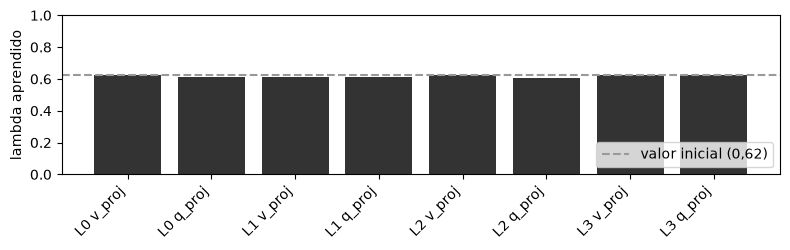

In [9]:
import matplotlib.pyplot as plt

lams = {name: m.lam.item() for name, m in rlora_clf.named_modules() if isinstance(m, RLoRALinear)}
for name, lam in lams.items():
    print(f"{name:60s} lambda = {lam:.4f}")

labels = [n.replace("encoder.layers.", "L").replace(".self_attn.", " ") for n in lams]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(range(len(lams)), list(lams.values()), color="0.2")
ax.axhline(1 / (1 + math.exp(-0.5)), color="0.6", linestyle="--", label="valor inicial (0,62)")
ax.set_xticks(range(len(lams)), labels, rotation=45, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("lambda aprendido")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 3.3 Fusionar: LoRA puede, R-LoRA no

Tras entrenar, la actualización de LoRA se puede plegar en el peso congelado
($W = W_0 + \tfrac{\alpha}{r}BA$) y el adaptador desaparece en inferencia. `peft` lo hace con
`merge_and_unload()`, y las salidas no cambian. Para R-LoRA no hay matriz que sumar: la
actualización depende de $\lVert x\rVert$, que cambia con cada entrada. La celda de abajo
intenta la fusión ingenua y muestra que cambia la salida del modelo.

In [10]:
import copy

with torch.no_grad():
    # LoRA: fusionar y comparar logits
    before = lora_clf(input_features=X_val).logits
    merged = copy.deepcopy(lora_clf).merge_and_unload()
    after = merged(input_features=X_val).logits
    print(f"LoRA   max |logits antes - después de fusionar| = {(before - after).abs().max().item():.2e}")

    # R-LoRA: una fusión ingenua W0 + (alpha/r) B A ignora T_lambda
    naive = copy.deepcopy(rlora_clf)
    for parent in list(naive.modules()):
        for name, child in list(parent.named_children()):
            if isinstance(child, RLoRALinear):
                child.base.weight += (child.lora_B.weight @ child.lora_A.weight) * child.scaling
                setattr(parent, name, child.base)
    before = rlora_clf(input_features=X_val).logits
    after = naive(input_features=X_val).logits
    print(f"R-LoRA max |logits antes - después de la fusión ingenua| = {(before - after).abs().max().item():.2e}")

LoRA   max |logits antes - después de fusionar| = 4.77e-07


R-LoRA max |logits antes - después de la fusión ingenua| = 1.09e+00


### 3.4 Guardar y recargar solo el adaptador

Sin `peft`, el adaptador es simplemente la parte entrenable del state dict: los tensores
`lora_A`, `lora_B` y `lambda_raw` más la cabeza nueva. Para recargarlo, se inyecta R-LoRA en
un modelo base limpio y se carga ese diccionario. Para desplegar, el sistema de ASR con R-LoRA
de ALBAYZIN 2026 fue un paso más allá: el modelo adaptado se guardó como un único modelo de
Hugging Face autocontenido, con su propio código, así que la inferencia es una sola llamada a
`from_pretrained`.

In [11]:
import tempfile
from pathlib import Path

trainable_names = {n for n, p in rlora_clf.named_parameters() if p.requires_grad}
adapter_state = {k: v for k, v in rlora_clf.state_dict().items() if k in trainable_names}

with tempfile.TemporaryDirectory() as tmp_dir:
    path = Path(tmp_dir) / "whisper_tiny_classifier_rlora.pt"
    torch.save(adapter_state, path)
    print(f"Adaptador guardado: {path.stat().st_size / 1e6:.2f} MB ({len(adapter_state)} tensores)")

    reloaded = WhisperForAudioClassification.from_pretrained(CHECKPOINT, num_labels=2)
    inject_rlora(reloaded, TARGETS, r=R, alpha=ALPHA, modules_to_save=HEADS)
    missing, unexpected = reloaded.load_state_dict(torch.load(path), strict=False)
    print("claves inesperadas:", unexpected, "| claves entrenables que faltan:", [k for k in missing if k in trainable_names])
    print(f"val accuracy tras recargar: {accuracy(reloaded, X_val, y_val):.3f}")

Adaptador guardado: 0.60 MB (28 tensores)


claves inesperadas: [] | claves entrenables que faltan: []


val accuracy tras recargar: 1.000


## 4. Parte B -- Whisper como extractor de embeddings con R-LoRA

La receta de la Parte B del tutorial de LoRA, con R-LoRA: adaptadores en `q_proj`, `v_proj`,
`fc1` y `fc2` del encoder (el propio embedding tiene que moverse, así que también se adaptan
las capas feed-forward), una *probe* lineal desechable para entrenarlos y una
`LogisticRegression` externa sobre embeddings promediados, antes y después.

In [12]:
from sklearn.linear_model import LogisticRegression
from transformers import WhisperModel

whisper_full = WhisperModel.from_pretrained(CHECKPOINT)
encoder = whisper_full.get_encoder()
torch.manual_seed(0)
inject_rlora(encoder, ("q_proj", "v_proj", "fc1", "fc2"), r=4, alpha=8)
trainable, total = count_trainable(encoder)
print(f"entrenables {trainable:,} de {total:,} ({100 * trainable / total:.2f}%)")


def embed(model, X):
    model.eval()
    with torch.no_grad():
        return model(input_features=X).last_hidden_state.mean(dim=1).numpy()


acc_before = LogisticRegression(max_iter=1000).fit(embed(encoder, X_train), y_train).score(embed(encoder, X_val), y_val)

scratch_probe = nn.Linear(whisper_full.config.d_model, 2)  # cabeza desechable
opt = torch.optim.AdamW([
    {"params": [p for p in encoder.parameters() if p.requires_grad], "lr": 1e-3 * scale},  # tasa ajustada, como en 3.1
    {"params": scratch_probe.parameters(), "lr": 1e-3},
])
t0 = time.time()
for epoch in range(3):
    encoder.train()
    perm = torch.randperm(X_train.shape[0])
    for i in range(0, X_train.shape[0], 4):
        idx = perm[i : i + 4]
        opt.zero_grad()
        pooled = encoder(input_features=X_train[idx]).last_hidden_state.mean(dim=1)
        loss = nn.functional.cross_entropy(scratch_probe(pooled), y_train[idx])
        loss.backward()
        opt.step()
    print(f"época {epoch} | loss {loss.item():.4f} | {time.time() - t0:.1f}s")

acc_after = LogisticRegression(max_iter=1000).fit(embed(encoder, X_train), y_train).score(embed(encoder, X_val), y_val)
print(f"\nval accuracy, LogisticRegression externa -- sin adaptar: {acc_before:.3f} | adaptado con R-LoRA: {acc_after:.3f}")

entrenables 86,032 de 8,294,416 (1.04%)


época 0 | loss 0.7746 | 11.2s


época 1 | loss 0.1592 | 20.9s


época 2 | loss 0.0016 | 30.6s



val accuracy, LogisticRegression externa -- sin adaptar: 1.000 | adaptado con R-LoRA: 1.000


## 5. Resumen

| | LoRA (`peft`) | R-LoRA (este notebook) |
|---|---|---|
| Actualización | $\tfrac{\alpha}{r}BAx$ | $\tfrac{\alpha}{r}BA\,T_\lambda(x)$ |
| Parámetros extra | -- | un λ por capa adaptada |
| Inicialización | $B = 0$ | $B = 0$, $\lambda_0 \approx 0.62$ |
| Fusión con $W_0$ tras entrenar | sí | no: la rama se ejecuta en inferencia |
| Dónde compensa (paper) | -- | pocos datos, representaciones concentradas: +12,4 Macro-F1 sobre LoRA en cuatro corpus clínicos |

**Ideas clave:**
- R-LoRA es un cambio de diez líneas sobre LoRA: normalizar la entrada del adaptador por su
  norma elevada a una potencia aprendible. Todo lo demás (dónde colocar los adaptadores, el
  rango, `modules_to_save`, el truco de la probe para embeddings) es igual que en el tutorial de LoRA.
- Comprueba las tres propiedades al implementarlo: identidad al inicializar, LoRA con
  λ = 0 y no linealidad en el resto de casos.
- No reutilices a ciegas la tasa de aprendizaje de LoRA: la rama ve una entrada reducida
  por $\lVert x\rVert^{\lambda}$, así que da a los adaptadores una tasa acorde o ajústala para cada método.
- Como envuelve `nn.Linear`, se aplica a cualquier Transformer. En Whisper-large-v3 para
  reconocimiento de habla dialectal alcanzó un 26,31 % de WER normalizado frente al 29,24 %
  de LoRA en el test ciego de ALBAYZIN 2026.
- Ten en cuenta el coste: no se puede fusionar, así que hay que servir el modelo adaptado completo.

**Referencias:**
- R-LoRA: Ramírez-Sánchez, Docío-Fernández, García-Caballero y García-Mateo, *Radial LoRA: Enhancing Parameter-Efficient Fine-Tuning for Clinical Speech Assessment*, IberSPEECH 2026 -- https://jmramirez.engineer/research/radial-lora-clinical-2026/
- Explicación: https://jmramirez.engineer/writing/radial-lora/
- LoRA: Hu et al., 2021 -- [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Whisper: Radford et al., 2022 -- [arXiv:2212.04356](https://arxiv.org/abs/2212.04356)
- La versión LoRA de este notebook: [whisper-peft-lora.ipynb](https://github.com/JMasr/ai-tutorials/blob/main/es/whisper-peft-lora.ipynb)